In [34]:
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
df= pd.read_csv("requirements_user_data.csv",parse_dates=["signup_date", "last_login"], dtype={'phone_code': str})

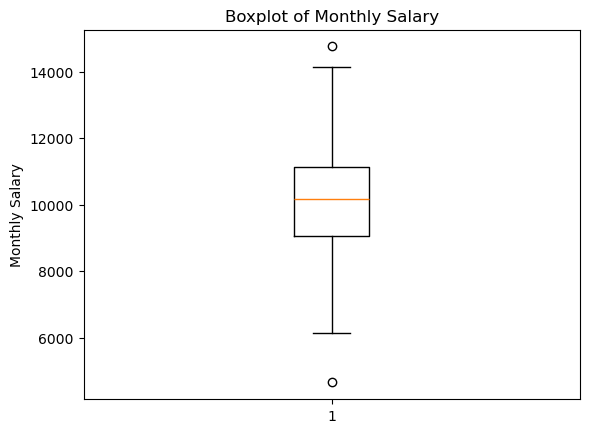

In [35]:
#TODO: Draw a box and whiskers diagram to detect outliers for the user salary
#HINT: use df.box_plot
plt.figure()
# WRITE CODE IN THIS LINE
plt.boxplot(df['monthly_salary'])
plt.title("Boxplot of Monthly Salary")
plt.ylabel("Monthly Salary")
plt.show()
#########Question to Answer#############:
# Explain the diagram


In [36]:
#TODO Calculate Lower Quartile of purchase_amount
#HINT Use quantile function
Q1 = df['purchase_amount'].quantile(0.25)

#TODO Calculate Upper Quartile
Q3 = df['purchase_amount'].quantile(0.75)

#TODO Calculate Inter Quartile range
IQR = Q3 - Q1

#TODO Calculate Lower bound
lower_bound = Q1 - 1.5 * IQR

#TODO Calculate Upper bound
upper_bound = Q3 + 1.5 * IQR

#TODO Extract the rows of the dfs that contain the outlier
df['is_outlier'] = (df['purchase_amount'] < lower_bound) | (df['purchase_amount'] > upper_bound)
outliers = df[df['is_outlier']]

#TODO Uncomment the following lines after completing the above tasks
print("Purchase Amount IQR Analysis")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))

#TODO Print the outliers user_id and purchase_amount 
print("user_id  purchase_amount")
print(outliers['user_id'], '\t \t', outliers['purchase_amount'])


Purchase Amount IQR Analysis
Q1: 1000.0
Q3: 1503.8825
IQR: 503.88249999999994
Lower Bound: 244.1762500000001
Upper Bound: 2259.7062499999997
Number of Outliers: 36
user_id  purchase_amount
25      26
27      28
31      32
52      53
57      58
61      62
64      65
65      66
76      77
87      88
88      89
103    104
111    112
114    115
118    119
131    132
136    137
142    143
166    167
174    175
188    189
199    200
202    203
204    205
226    227
227    228
241    242
246    247
250    251
251    252
262    263
270    271
276    277
278    279
283    284
284    285
Name: user_id, dtype: int64 	 	 25     10000.00
27      4639.90
31      2696.96
52      2411.72
57      3133.06
61      4035.92
64      2340.54
65      4526.81
76      3152.86
87      5609.14
88      2277.27
103     2682.23
111     3273.38
114     4764.79
118     2369.94
131     2660.55
136     3252.31
142     2393.62
166     2943.10
174     4620.12
188     2887.84
199     3303.25
202     2402.68
204     3338.80

In [37]:
#last login cant be in the future vaidation
today = datetime.today()
#TODO get all rows where the last_login is in the future
future_login = df[df['last_login'] > today]


#TODO Uncomment the following lines after completing the above tasks
print("\nFuture Last Login Dates:")
print("Count:", len(future_login))

#TODO Print all extracted rows, print only user_id and last_login
print(future_login[['user_id', 'last_login']])

#Questions to answer
#What kind of Validation dimension is this?
#ANSWER: Timeliness


Future Last Login Dates:
Count: 1
    user_id                 last_login
30       31 2026-03-09 20:16:36.593117


In [38]:
#TODO get all rows where the signup_date is later than the last_login
invalid_login_order = df[df['last_login'] < df['signup_date']]

#TODO Uncomment the following lines after completing the above tasks
print("\nLast Login Before Signup:")
print("Count:", len(invalid_login_order))
print(invalid_login_order[["user_id", "signup_date", "last_login"]])

#Questions to answer
#What kind of Validation dimension is this 
#ANSWER: Timeliness


Last Login Before Signup:
Count: 38
     user_id                signup_date                 last_login
1          1 2025-07-14 20:16:36.593117 2025-05-27 20:16:36.593117
13        14 2025-12-24 20:16:36.593117 2025-12-05 20:16:36.593117
14        15 2025-12-28 20:16:36.593117 2025-08-17 20:16:36.593117
20        21 2026-01-04 20:16:36.593117 2025-07-26 20:16:36.593117
32        33 2026-02-14 20:16:36.593117 2025-05-07 20:16:36.593117
33        34 2025-04-07 20:16:36.593117 2025-02-16 20:16:36.593117
35        36 2026-03-04 20:16:36.593117 2026-01-27 20:16:36.593117
41        42 2025-08-02 20:16:36.593117 2025-06-28 20:16:36.593117
42        43 2025-08-22 20:16:36.593117 2025-06-15 20:16:36.593117
64        65 2025-10-08 20:16:36.593117 2025-03-28 20:16:36.593117
65        66 2025-11-26 20:16:36.593117 2025-05-05 20:16:36.593117
71        72 2025-08-05 20:16:36.593117 2025-03-22 20:16:36.593117
86        87 2025-10-04 20:16:36.593117 2025-07-08 20:16:36.593117
103      104 2025-11-05 2

In [39]:
#Country phone number check
countries = {
    "USA": "+1",
    "UK": "+44",
    "Canada": "+1",
    "Australia": "+61",
    "Germany": "+49"
}
#TODO using the given correct values of country codes extract the rows where the phone_code mismatches the user country
# HINT: You can do this on 2 steps, you can use the map function
df['correct_phone_code'] = df['country'].map(countries)
mismatches = df[(df['phone_code'] != df['correct_phone_code'] )]

#TODO Uncomment the following lines after completing the above tasks
print("\nCountry ↔ Phone Code Mismatches:")
print("Count:", len(mismatches))


#TODO Print all mismatches, print user_id, country, phone_code, correct_phone_code
print(mismatches[["user_id", "country", "phone_code", 'correct_phone_code']])


Country ↔ Phone Code Mismatches:
Count: 2
    user_id    country phone_code correct_phone_code
40       41      Egypt         +1                NaN
45       46  Australia       +999                +61


In [50]:
#TODO Get the country distribution
#HINT: use value_counts
country_distribution = df['country'].value_counts(normalize=True) * 100

#TODO Uncomment the following lines after completing the above tasks
print("\nCountry Distribution (%):")
print(country_distribution)


#TODO Get the dominant countries where the distribution is greater than 60%
dominant_country = country_distribution[country_distribution > 60]

#TODO print the dominant_country
print(dominant_country)


#Questions to answer
#What kind of Validation dimension is this 
#ANSWER: distribution profile



Country Distribution (%):
country
USA          69.666667
Australia    10.333333
Canada        7.666667
Germany       6.666667
UK            5.333333
Egypt         0.333333
Name: proportion, dtype: float64
country
USA    69.666667
Name: proportion, dtype: float64
